# Star temperature and luminosity

This notebook reads the star dataset, estimates each star's distance, luminosity, and temperature, then displays the stars on a Hertzsprung–Russell-style diagram.

The calculations assume `parallax_arcsec` is measured in arcseconds and `peakLam_m` in meters. The flux column name indicates units of solar luminosities per square centimeter (`L_sun/cm^2`); under that assumption, multiplying by the area of a sphere gives luminosity in solar units.

## 1. Import the tools

Pandas handles the table, NumPy provides π, and Matplotlib creates the diagram.

In [38]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 2. Find and load the dataset

The search checks both the notebook's current folder and a `Day03-assignment` subfolder, so the notebook works whether Jupyter was opened from the assignment folder or its parent. If neither location contains the CSV, the code reports the paths it checked.

In [39]:
filename = "ASTRM402_data.csv"
candidate_paths = [Path.cwd() / filename, Path.cwd() / "Day03-assignment" / filename]
csv_path = next((path for path in candidate_paths if path.is_file()), None)

if csv_path is None:
    checked_paths = "\n".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(f"Could not find {filename}. Checked:\n{checked_paths}")

stars = pd.read_csv(csv_path)
print(f"Loaded {len(stars):,} stars from: {csv_path.resolve()}")

Loaded 9,171 stars from: C:\Users\erezd\OneDrive\שולחן העבודה\אוניברסיטה\תואר שני\קורסים\Python programming with AI\Day03-assignment\ASTRM402_data.csv


## 3. Inspect the data

Check the table size, column names, and a few example rows before using the measurements.

In [40]:
print(f"Rows: {stars.shape[0]:,}; columns: {stars.shape[1]}")
print("Columns:", stars.columns.tolist())
stars.head()

Rows: 9,171; columns: 6
Columns: ['id', 'ra_deg', 'dec_deg', 'parallax_arcsec', 'flux_Lsuncm2', 'peakLam_m']


,id,ra_deg,dec_deg,parallax_arcsec,flux_Lsuncm2,peakLam_m
0,Gaia DR3 5192616270720,44.973696,0.155204,0.008054,3.520000e-45,8.330000e-07
1,Gaia DR3 7116761616256,45.000073,0.214145,0.005185,2.300000e-45,8.700000e-07
2,Gaia DR3 7284264691456,45.062277,0.216004,0.006227,2.710000e-44,6.740000e-07
3,Gaia DR3 7632157690368,45.034343,0.235390,0.005602,6.800000e-42,5.920000e-07
4,Gaia DR3 11510512362368,45.255646,0.290323,0.006119,1.050000e-45,8.980000e-07


## 4. Check required columns and measurements

The calculations need the identifier plus parallax, flux, and peak wavelength. We also retain the sky coordinates. Measurement columns are converted to numbers; malformed text and nonpositive calculation inputs stop the notebook with an error. Rows with missing numeric measurements are reported and excluded because their derived values cannot be calculated.

In [41]:
required_columns = [
    "id",
    "ra_deg",
    "dec_deg",
    "parallax_arcsec",
    "flux_Lsuncm2",
    "peakLam_m",
]
missing_columns = [column for column in required_columns if column not in stars.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

measurement_columns = [
    "ra_deg",
    "dec_deg",
    "parallax_arcsec",
    "flux_Lsuncm2",
    "peakLam_m",
]
for column in measurement_columns:
    stars[column] = pd.to_numeric(stars[column], errors="raise")

incomplete_rows = stars[measurement_columns].isna().any(axis=1)
if incomplete_rows.any():
    missing_counts = stars.loc[incomplete_rows, measurement_columns].isna().sum()
    print(f"Excluding {int(incomplete_rows.sum())} rows with missing measurements.")
    print("Missing values by column:")
    print(missing_counts[missing_counts > 0].to_string())
    print("Example excluded IDs:", stars.loc[incomplete_rows, "id"].head(10).tolist())
    stars = stars.loc[~incomplete_rows].copy()

if stars.empty:
    raise ValueError("No complete rows remain for the star calculations.")

positive_columns = ["parallax_arcsec", "flux_Lsuncm2", "peakLam_m"]
for column in positive_columns:
    if (stars[column] <= 0).any():
        raise ValueError(f"Every value in {column} must be positive for this calculation.")

print("Required columns and measurement checks passed.")

Excluding 40 rows with missing measurements.
Missing values by column:
peakLam_m    40
Example excluded IDs: ['Gaia DR3 756571374829440', 'Gaia DR3 1068931460633216', 'Gaia DR3 3143095722559872', 'Gaia DR3 4307169298670464', 'Gaia DR3 5352358179676672', 'Gaia DR3 8777268181161216', 'Gaia DR3 11589475327804160', 'Gaia DR3 12695171708571776', 'Gaia DR3 14141304376849280', 'Gaia DR3 15128081702947072']
Required columns and measurement checks passed.


## 5. Calculate distance, luminosity, and temperature

For a positive parallax `p` in arcseconds, distance in parsecs is `1 / p`. Convert parsecs to centimeters before using the inverse-square flux relation:

$$L/L_\odot = 4\pi d_{\mathrm{cm}}^2 F$$

Here `F` is assumed to be in `L_sun/cm^2`, so the result is in solar luminosities. Wien's displacement law estimates temperature from the peak wavelength: `T = 2.897771955e-3 m K / peak wavelength (m)`. This is an estimate based on blackbody radiation.

In [42]:
PARSEC_TO_CM = 3.085677581e18
WIEN_DISPLACEMENT_M_K = 2.897771955e-3

stars["distance_pc"] = 1 / stars["parallax_arcsec"]
stars["distance_cm"] = stars["distance_pc"] * PARSEC_TO_CM
stars["luminosity_Lsun"] = (
    4 * np.pi * stars["distance_cm"] ** 2 * stars["flux_Lsuncm2"]
)
stars["temperature_K"] = WIEN_DISPLACEMENT_M_K / stars["peakLam_m"]

if not np.isfinite(stars[["distance_pc", "luminosity_Lsun", "temperature_K"]].to_numpy()).all():
    raise ValueError("A derived value is not finite; check the input measurements.")
if (stars["luminosity_Lsun"] <= 0).any():
    raise ValueError("Luminosity must be positive to display on a logarithmic axis.")

stars[["distance_pc", "luminosity_Lsun", "temperature_K"]].describe()

,distance_pc,luminosity_Lsun,temperature_K
count,9131.000000,9131.000000,9131.000000
mean,143.139114,1.331292,4063.202848
std,40.595825,10.903311,1140.537668
min,7.223498,0.000115,2900.672628
25%,116.085396,0.006511,3365.588798
50%,150.148752,0.018541,3555.548411
75%,176.850828,0.168669,4478.782002
max,199.997160,426.817607,12654.026004


## 6. Review the derived values

Sort by estimated temperature to inspect the coolest stars first. The table keeps each star's ID alongside the measurements used and the calculated properties.

In [43]:
display_columns = [
    "id",
    "parallax_arcsec",
    "flux_Lsuncm2",
    "peakLam_m",
    "distance_pc",
    "luminosity_Lsun",
    "temperature_K",
]
stars.sort_values("temperature_K")[display_columns].head(10)

,id,parallax_arcsec,flux_Lsuncm2,peakLam_m,distance_pc,luminosity_Lsun,temperature_K
7960,Gaia DR3 39749651743741696,0.012163,1.140000e-45,9.990000e-07,82.219877,0.000922,2900.672628
8964,Gaia DR3 44210404777324544,0.010942,6.050000e-45,9.990000e-07,91.388958,0.006046,2900.672628
8798,Gaia DR3 43513658003551360,0.005640,1.160000e-45,9.990000e-07,177.306128,0.004363,2900.672628
743,Gaia DR3 3591765186114816,0.018633,2.740000e-45,9.970000e-07,53.668402,0.000944,2906.491429
7576,Gaia DR3 37997472589268864,0.011913,1.050000e-45,9.970000e-07,83.944921,0.000885,2906.491429
6393,Gaia DR3 32496242253308544,0.017070,1.980000e-45,9.970000e-07,58.582466,0.000813,2906.491429
3662,Gaia DR3 18437611702558464,0.009223,3.140000e-45,9.960000e-07,108.421711,0.004416,2909.409593
1460,Gaia DR3 7193932782026496,0.017459,1.880000e-45,9.950000e-07,57.278483,0.000738,2912.333623
8262,Gaia DR3 41140087276587904,0.012543,1.380000e-45,9.920000e-07,79.728693,0.001050,2921.141084
1169,Gaia DR3 5837071009282816,0.032610,6.490000e-45,9.920000e-07,30.665591,0.000730,2921.141084


## 7. Plot the stars

This is a Hertzsprung–Russell-style diagram: estimated temperature is on the horizontal axis and luminosity on the vertical axis. The temperature axis is reversed so hotter stars appear on the left, as is conventional. Luminosity uses a logarithmic scale because stellar luminosities span a wide range. Points are plotted in temperature order and colored by temperature, from red for the coolest stars through white to blue for the hottest stars.

The shaded regions are approximate guides only: real star classes do not have exact rectangular boundaries. The expanded axes show all four reference areas; the stars in this dataset occupy only part of the full diagram.

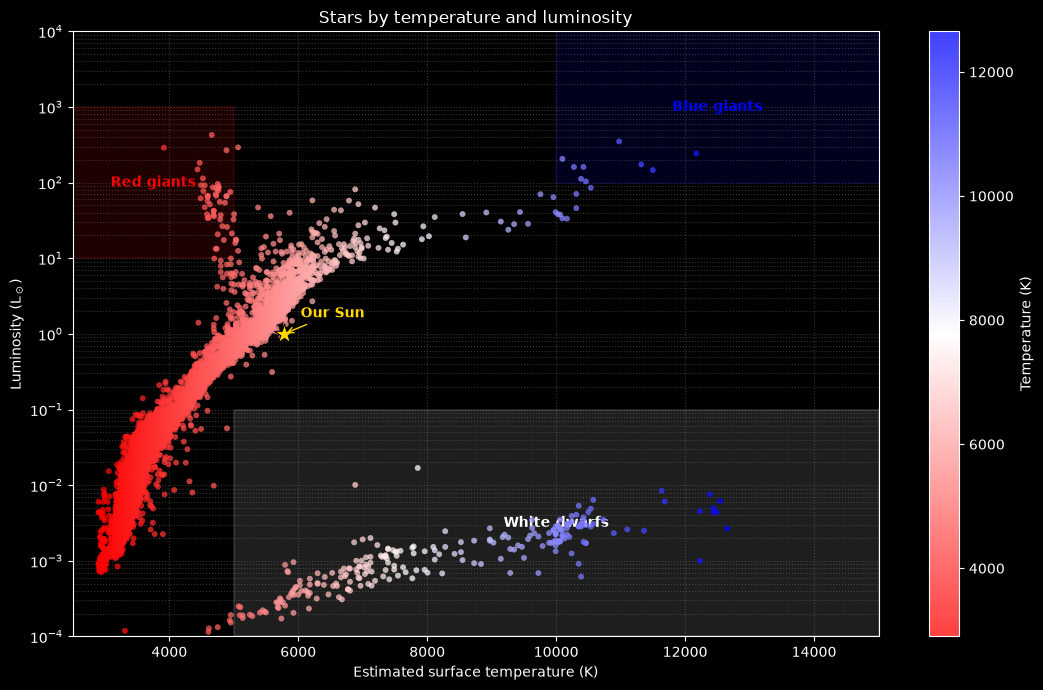

In [44]:
from matplotlib.colors import LinearSegmentedColormap

ordered_stars = stars.sort_values("temperature_K")
temperature_cmap = LinearSegmentedColormap.from_list(
    "cold_to_hot", ["red", "white", "blue"]
)

fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor("black")
ax.set_facecolor("black")
ax.set_yscale("log")
ax.set_xlim(15000, 2500)
ax.set_ylim(1e-4, 1e4)

regions = [
    {"name": "Red giants", "temperature": (2500, 5000), "luminosity": (10, 1e3), "color": "red"},
    {"name": "Blue giants", "temperature": (10000, 15000), "luminosity": (1e2, 1e4), "color": "blue"},
    {"name": "White dwarfs", "temperature": (5000, 15000), "luminosity": (1e-4, 1e-1), "color": "white"},
]
for region in regions:
    temp_min, temp_max = region["temperature"]
    luminosity_min, luminosity_max = region["luminosity"]
    ax.add_patch(
        plt.Rectangle(
            (temp_min, luminosity_min),
            temp_max - temp_min,
            luminosity_max - luminosity_min,
            facecolor=region["color"],
            edgecolor=region["color"],
            alpha=0.12,
            linewidth=1.5,
            zorder=1,
        )
    )
    label_luminosity = np.sqrt(luminosity_min * luminosity_max)
    ax.text(
        (temp_min + temp_max) / 2,
        label_luminosity,
        region["name"],
        color=region["color"],
        ha="center",
        va="center",
        fontsize=10,
        weight="bold",
        zorder=4,
    )
points = ax.scatter(
    ordered_stars["temperature_K"],
    ordered_stars["luminosity_Lsun"],
    c=ordered_stars["temperature_K"],
    cmap=temperature_cmap,
    s=18,
    alpha=0.75,
    edgecolors="none",
    zorder=3,
)
sun_temperature_K = 5778
sun_luminosity_Lsun = 1.0
ax.scatter(
    sun_temperature_K,
    sun_luminosity_Lsun,
    marker="*",
    s=220,
    color="gold",
    edgecolors="black",
    linewidths=0.8,
    zorder=5,
)
ax.annotate(
    "Our Sun",
    xy=(sun_temperature_K, sun_luminosity_Lsun),
    xytext=(12, 12),
    textcoords="offset points",
    color="gold",
    weight="bold",
    arrowprops={"arrowstyle": "->", "color": "gold"},
    zorder=6,
)
ax.invert_xaxis()
ax.set_xlabel("Estimated surface temperature (K)", color="white")
ax.set_ylabel("Luminosity (L$_\\odot$)", color="white")
ax.set_title("Stars by temperature and luminosity", color="white")
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")
ax.grid(True, which="both", linestyle=":", color="gray", alpha=0.4)
colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label("Temperature (K)", color="white")
colorbar.ax.tick_params(colors="white")
colorbar.outline.set_edgecolor("white")
fig.tight_layout()
plt.show()